# DQN sur LunarLander-v3

Un agent DQN apprend à poser le module lunaire. Le notebook se lit de haut en bas et doit tourner avec *Restart & Run All*.

1. Setup et configuration
2. Environnement
3. Baseline aléatoire
4. Composants du DQN (replay buffer, réseau, epsilon-greedy, apprentissage)
5. Entraînement
6. Résultats
7. Expériences
8. Conclusion

## 1. Setup

In [103]:
import random
from collections import Counter

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

### Configuration

Tous les hyperparamètres sont dans un seul dictionnaire, pour pouvoir lancer une expérience avec une autre configuration sans toucher au reste du code.

Ces valeurs forment la **configuration de référence**. Elles sont provisoires : elles seront justifiées (ou changées) par les expériences de la section 7.

Méthode pour les choisir :
- on change **un seul** paramètre à la fois, le reste reste à la valeur de référence,
- même budget d'entraînement et mêmes seeds pour chaque essai,
- mêmes mesures : score moyen sur 100 épisodes sans exploration, et nombre d'épisodes pour atteindre une moyenne mobile d'au moins 200.

In [104]:
CONFIG = {
    "gamma": 0.99,
    "learning_rate": 1e-3,
    "batch_size": 64,
    "buffer_capacity": 100_000,
    "eps_start": 1.0,
    "eps_end": 0.01,
    "eps_decay": 0.995,
    "target_update_every": 1000,
    "hidden_size": 128,
    "n_episodes": 600,
}

## 2. Environnement

In [105]:
env = gym.make("LunarLander-v3")
env.action_space.seed(SEED)
state, info = env.reset(seed=SEED)
state_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

print("State dimension:", state_dim)
print("Number of actions:", n_actions)

State dimension: 8
Number of actions: 4


## 3. Baseline aléatoire

### Agent aléatoire

Pour savoir si un agent apprend, il faut un point de comparaison. L'agent aléatoire choisit au hasard une des 4 actions à chaque step, sans regarder l'état : c'est le score à battre.

Il reçoit quand même `state` en argument, pour avoir la même interface que le futur agent DQN (`agent(state=state)` renvoie une action). Il utilise `random.randrange`, dont le générateur est seedé, donc la baseline est reproductible.

In [106]:
def random_agent(*, state):
    return random.randrange(n_actions)

print("Random action:", random_agent(state=state))

Random action: 0


### Jouer un épisode

`run_episode(env=env, agent=agent)` joue un épisode complet : `reset`, puis `step` en boucle jusqu'à la fin. Elle renvoie le reward total, le nombre de steps et la raison de fin.

`agent` est n'importe quelle fonction qui prend un état et renvoie une action : `random_agent` ici, et plus tard l'agent DQN joué sans exploration. La même fonction sert donc à tous les agents.

La boucle s'arrête quand `terminated` ou `truncated` est vrai, mais les deux restent des variables séparées, car ils n'ont pas le même sens :
- `terminated` : l'épisode est vraiment fini. Trois causes possibles : `crash` (le corps du lander touche le sol), `out_of_viewport` (`abs(x) >= 1`), ou `at_rest` (le lander est posé et ne bouge plus).
- `truncated` : l'épisode a été coupé au nombre maximum de steps, le lander aurait pu continuer.

Le crash est testé en premier : un crash qui projette le lander hors de l'écran compte comme un crash.

La cellule suivante rejoue 100 épisodes aléatoires et calcule le score moyen, l'écart-type, la répartition des raisons de fin et l'histogramme des scores.

In [107]:
def run_episode(*, env, agent, seed=None):
    state, _ = env.reset(seed=seed)
    total_reward = 0.0
    steps = 0

    while True:
        action = agent(state=state)
        next_state, reward, terminated, truncated, _ = env.step(action)

        total_reward += reward
        steps += 1

        if terminated or truncated:
            if terminated:
                if env.unwrapped.game_over:
                    reason = "crash"
                elif abs(next_state[0]) >= 1.0:
                    reason = "out_of_viewport"
                else:
                    reason = "at_rest"
            else:
                reason = "truncated"
            return total_reward, steps, reason

        state = next_state

Random agent over 100 episodes
Mean reward: -173.4
Std reward:  110.0
Mean steps:  88.2
End reasons: {'crash': 93, 'out_of_viewport': 7}


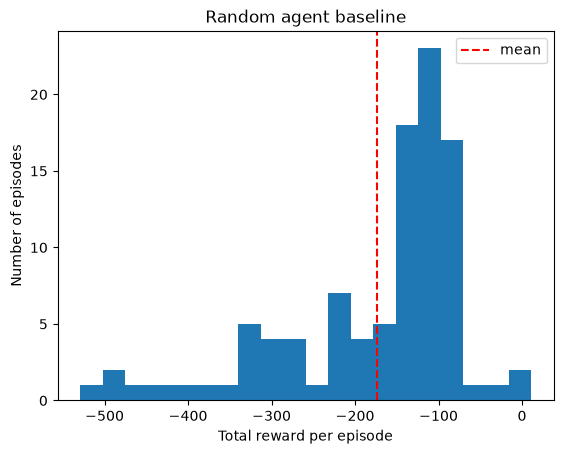

In [108]:
N_EVAL = 100

rewards, steps_list, reasons = [], [], []
for _ in range(N_EVAL):
    total_reward, steps, reason = run_episode(env=env, agent=random_agent)
    rewards.append(total_reward)
    steps_list.append(steps)
    reasons.append(reason)

print(f"Random agent over {N_EVAL} episodes")
print(f"Mean reward: {np.mean(rewards):.1f}")
print(f"Std reward:  {np.std(rewards):.1f}")
print(f"Mean steps:  {np.mean(steps_list):.1f}")
print("End reasons:", dict(Counter(reasons)))

plt.hist(rewards, bins=20)
plt.axvline(np.mean(rewards), color="red", linestyle="--", label="mean")
plt.xlabel("Total reward per episode")
plt.ylabel("Number of episodes")
plt.title("Random agent baseline")
plt.legend()
plt.show()

## 4. Composants du DQN

### Replay buffer

Les steps consécutifs d'un épisode se ressemblent beaucoup, apprendre dans l'ordre est instable. Le buffer garde les dernières expériences `(state, action, reward, next_state, done)` jusqu'à une capacité fixe (les plus anciennes sont remplacées), et `sample` en tire un lot au hasard sous forme de 5 tenseurs.

On stockera `done = terminated` uniquement : un épisode `truncated` n'est pas vraiment fini, son futur doit rester pris en compte dans la target.

In [ ]:
class ReplayBuffer:
    def __init__(self, *, capacity):
        self.capacity = capacity
        self.buffer = []    

    def __len__(self):
        return len(self.buffer)
    
    def push(self, *, state, action, reward, next_state, done):
        if len(self.buffer) >= self.capacity:
            self.buffer.pop(0)
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, *, batch_size):
        if batch_size > len(self.buffer):
            raise ValueError("Batch size exceeds buffer size.")
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = [], [], [], [], []
        for exp in batch:
            states.append(exp[0])
            actions.append(exp[1])
            rewards.append(exp[2])
            next_states.append(exp[3])
            dones.append(exp[4])

        states = torch.tensor(np.array(states), dtype=torch.float32)
        actions = torch.tensor(actions, dtype=torch.long)
        rewards = torch.tensor(rewards, dtype=torch.float32)
        next_states = torch.tensor(np.array(next_states), dtype=torch.float32)
        dones = torch.tensor(dones, dtype=torch.float32)
        return states, actions, rewards, next_states, dones

### Q-network (réseau de neurones)

Le réseau prend l'état du lander (8 nombres) et renvoie une Q-value par action (4 nombres). L'agent jouera l'action dont la Q-value est la plus grande.

```
état (8)  ->  Linear(8, 128)  ->  ReLU  ->  Linear(128, 128)  ->  ReLU  ->  Linear(128, 4)  ->  Q-values (4)
```

- **`Linear`** mélange les nombres d'entrée avec des poids réglables. Ce sont ces poids que l'entraînement ajuste.
- **`ReLU`** met les valeurs négatives à 0. Sans elle, enchaîner plusieurs `Linear` reviendrait à un seul `Linear` : le réseau ne saurait apprendre que des relations très simples.
- Pas de `ReLU` en sortie : une Q-value peut être négative, on veut la lire telle quelle.
- La taille d'entrée (`state_dim`) et de sortie (`n_actions`) sont lues dans l'environnement. La taille des couches cachées (128) est un hyperparamètre.

#### Pourquoi une classe avec `forward`, et pourquoi on écrit `network(x)`

`QNetwork` hérite de `nn.Module`, la classe de base des réseaux PyTorch.

- Dans `__init__`, on **construit** les couches, une seule fois. Leurs poids vivent dans l'objet et sont modifiés par l'entraînement.
- Dans `forward`, on décrit **le calcul** : dans quel ordre `x` traverse les couches.
- On n'appelle pas `network.forward(x)` mais `network(x)`. En Python, un objet dont la classe définit `__call__` peut être appelé comme une fonction. `nn.Module` définit cette méthode, et elle appelle notre `forward` en ajoutant quelques opérations internes de PyTorch autour (hooks, suivi des calculs).

```
network(x)  ->  nn.Module.__call__  ->  QNetwork.forward(x)  ->  self.network(x)  ->  Q-values
```

Si on oublie de définir `forward`, `network(x)` lève une `NotImplementedError`.

Les formes attendues : un état seul `(8,)` donne `(4,)`, un lot de 32 états `(32, 8)` donne `(32, 4)`. Le lot sert à l'apprentissage, qui traite plusieurs expériences d'un coup.

In [ ]:
from torch import nn


class QNetwork(nn.Module):
    def __init__(self, *, state_dim, n_actions, hidden):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions)
        )
    
    def forward(self, x):
        return self.network(x)
    
network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=CONFIG["hidden_size"])
print(network(torch.zeros((1, state_dim))))

tensor([[ 0.0489, -0.0024,  0.0125,  0.1445]], grad_fn=<AddmmBackward0>)


### Sélection d'action epsilon-greedy

Avec une probabilité epsilon, l'agent joue une action au hasard (exploration). Sinon il joue l'action de plus grande Q-value (exploitation). Epsilon part haut et décroît, et vaut 0 en évaluation : l'agent n'explore plus.

In [111]:
def choose_action(*, network, state, epsilon):
    if random.random() < epsilon:
        return random.randrange(n_actions)
    else:
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            q_values = network(state_tensor)
        return torch.argmax(q_values).item()
    
print("Epsilon-greedy action:", choose_action(network=network, state=state, epsilon=1))
print("Epsilon-greedy action:", choose_action(network=network, state=state, epsilon=0))

Epsilon-greedy action: 2
Epsilon-greedy action: 3


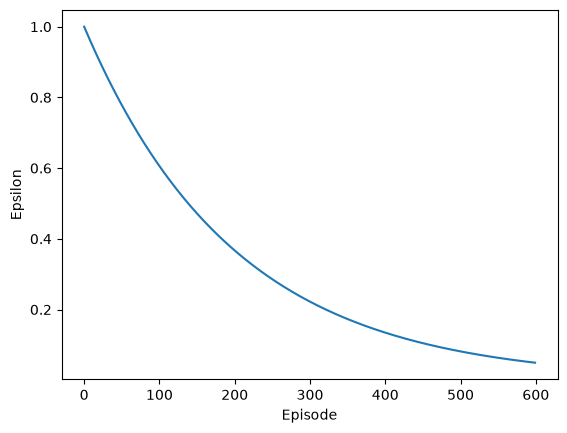

In [112]:

def epsilon_at(*, episode, config):
    eps = config["eps_start"] * config["eps_decay"] ** episode
    return max(config["eps_end"], eps)

epsilons = []
for episode in range(CONFIG["n_episodes"]):
    epsilons.append(epsilon_at(episode=episode, config=CONFIG))

plt.plot(epsilons)
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.show()

In [ ]:
target_network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=CONFIG["hidden_size"])
target_network.load_state_dict(network.state_dict())

optimizer = torch.optim.Adam(network.parameters(), lr=CONFIG["learning_rate"])

def learn(*, buffer, network, target_network, optimizer, config):
    if len(buffer) < config["batch_size"]:
        return None

    # 1. Un lot d'expériences passées, tirées au hasard
    states, actions, rewards, next_states, dones = buffer.sample(batch_size=config["batch_size"])

    # 2. Prédiction : ce que le réseau croit, pour l'action réellement jouée
    q_values = network(states)
    predicted = []
    for i in range(len(actions)):
        predicted.append(q_values[i, actions[i]])
    predicted = torch.stack(predicted)

    # 3. Cible de Bellman : reward vécu + valeur estimée du futur
    #    no_grad : la cible est une constante, on n'entraîne pas le target_network
    with torch.no_grad():
        next_q_values = target_network(next_states)
        best_next = next_q_values.max(dim=1).values
        targets = rewards + config["gamma"] * best_next * (1 - dones)

    # 4. Écart entre prédiction et cible
    loss = nn.functional.mse_loss(predicted, targets)

    # 5. Mise à jour des poids de network uniquement
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item()
